# Olist - EDA Đánh giá & Giao hàng, Đặc trưng Trải nghiệm Khách hàng

**Bộ dữ liệu:** Olist Brazilian E-Commerce (9 file CSV, ~100k đơn hàng).

**Mục tiêu của notebook**

| Nhiệm vụ | Nội dung | Đầu ra |
|---|---|---|
| 1 | EDA chất lượng giao hàng và đánh giá (review) | 8 biểu đồ PNG trong `figures/` |
| 2 | Đặc trưng trải nghiệm theo `customer_unique_id` | `experience_features.csv` |

**Sơ đồ kết nối dữ liệu**

```
orders (1 dòng / đơn)
  ├── customer_id ──> customers      : customer_unique_id, customer_state, customer_city
  ├── order_id    ──> order_items     : price, freight_value   (nhiều dòng / đơn -> gộp SUM)
  └── order_id    ──> order_reviews   : review_score           (có thể nhiều review -> gộp MEAN)
```

> **Lưu ý quan trọng:** `customer_id` bị lặp lại khi một khách mua nhiều đơn, nên mọi phép
> tổng hợp theo khách hàng **bắt buộc** dùng `customer_unique_id`.

In [1]:
# ====================================================================
# 0. CẤU HÌNH: đường dẫn, thư viện, style biểu đồ tiếng Việt
# ====================================================================
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")                 # chỉ render ra file ảnh
import matplotlib.pyplot as plt
from scipy import stats as sps

# Notebook đặt cùng thư mục với các file CSV; tự nhận diện khi chạy ở nơi khác.
ROOT = Path.cwd()
DATA_DIR = ROOT / "data" / "raw" if (ROOT / "data" / "raw" / "olist_orders_dataset.csv").exists() else (ROOT if (ROOT / "olist_orders_dataset.csv").exists() else Path("D:/KTDL LT"))
FIG_DIR = Path.cwd() / "figures"
FIG_DIR.mkdir(exist_ok=True)

assert DATA_DIR.exists(), f"Không tìm thấy thư mục dữ liệu: {DATA_DIR}"
print("Thư mục dữ liệu :", DATA_DIR)
print("Thư mục biểu đồ :", FIG_DIR)

# DejaVu Sans có đầy đủ dấu tiếng Việt -> không cần cài thêm font.
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,                      # yêu cầu: PNG dpi 200
    "font.family": "DejaVu Sans",
    "axes.unicode_minus": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
})
# Cho phép xem đầy đủ cột khi in DataFrame ở notebook
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
C_OK, C_LATE, C_MAIN, C_ACCENT = "#2E8B57", "#D9534F", "#1F6FEB", "#F2A007"
SAVED_FIGS = []          # lưu đường dẫn ảnh để nhúng ngược vào notebook

def savefig(fig, filename):
    "Lưu biểu đồ vào figures/ (dpi 200), hiển ảnh inline nếu chạy trong Jupyter, rồi đóng fig."
    path = FIG_DIR / filename
    fig.savefig(path, dpi=200, bbox_inches="tight")
    SAVED_FIGS.append(path)
    plt.close(fig)
    try:                                  # chỉ có tác dụng khi chạy bằng kernel Jupyter
        from IPython.display import Image, display
    except ImportError:
        pass
    else:
        px_w = int.from_bytes(path.read_bytes()[16:20], "big")   # chiều rộng ảnh PNG
        display(Image(filename=str(path), width=min(round(px_w * 96 / 200), 980)))
    print("  -> đã lưu", path.name)

Thư mục dữ liệu : C:\Users\Admin\Downloads\ktdl\data\raw
Thư mục biểu đồ : C:\Users\Admin\Downloads\ktdl\figures


## Nhiệm vụ 1 - EDA đánh giá và giao hàng

### 1.1. Nạp và kết nối dữ liệu

Hai bảng phụ được gộp về mức **một dòng một đơn** trước khi `merge`, tránh hiện tượng
"nổ" số dòng khi một đơn có nhiều `order_item` hoặc nhiều review.

In [2]:
# --------------------------------------------------------------------
# 1. Nạp 4 bảng cần thiết và ép kiểu ngày tháng ngay khi đọc
# --------------------------------------------------------------------
orders = pd.read_csv(
    DATA_DIR / "olist_orders_dataset.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_estimated_delivery_date",
        "order_delivered_customer_date",
    ],
)
customers = pd.read_csv(DATA_DIR / "olist_customers_dataset.csv")
items = pd.read_csv(
    DATA_DIR / "olist_order_items_dataset.csv",
    usecols=["order_id", "price", "freight_value"],
)
reviews = pd.read_csv(
    DATA_DIR / "olist_order_reviews_dataset.csv",
    usecols=["review_id", "order_id", "review_score"],
)

for name, tbl in [("orders", orders), ("customers", customers),
                  ("order_items", items), ("order_reviews", reviews)]:
    print(f"{name:<13} {tbl.shape[0]:>8,} dòng x {tbl.shape[1]} cột")

orders          99,441 dòng x 8 cột
customers       99,441 dòng x 5 cột
order_items    112,650 dòng x 3 cột
order_reviews   99,224 dòng x 3 cột


In [3]:
# --------------------------------------------------------------------
# 2. Gộp order_items / order_reviews về mức đơn hàng
# --------------------------------------------------------------------
order_items = items.groupby("order_id", as_index=False).agg(
    price=("price", "sum"),                   # tổng giá trị hàng của đơn
    freight_value=("freight_value", "sum"),   # tổng phí ship của đơn
)
order_reviews = reviews.groupby("order_id", as_index=False).agg(
    n_reviews=("review_id", "count"),
    review_score=("review_score", "mean"),  # điểm trung bình của đơn
)
print("order_items   ->", f"{len(order_items):,} đơn")
print("order_reviews ->", f"{len(order_reviews):,} đơn,",
      f"{(order_reviews['n_reviews'] > 1).sum():,} đơn có hơn 1 review")

order_items   ->

 98,666 đơn
order_reviews -> 98,673 đơn, 547 đơn có hơn 1 review


In [4]:
# --------------------------------------------------------------------
# 3. Kết nối 4 bảng quanh bảng 'orders'
# --------------------------------------------------------------------
df = (
    orders
    .merge(
        customers[["customer_id", "customer_unique_id",
                   "customer_city", "customer_state"]],
        on="customer_id", how="left",
    )
    .merge(order_items, on="order_id", how="left")
    .merge(order_reviews, on="order_id", how="left")
)

# Kiểm tra tính toàn vẹn sau merge
print("Số dòng sau merge      :", f"{len(df):,}", "(bằng số đơn gốc => merge không nhân bản dòng)")
print("customer_id duy nhất   :", f"{df['customer_id'].nunique():,}")
print("customer_unique_id     :", f"{df['customer_unique_id'].nunique():,}", "=> 1 khách có thể có nhiều customer_id")
print("Đơn có review          :", f"{df['review_score'].notna().sum():,}",
      f"({df['review_score'].notna().mean():.1%})")
print("Đơn có items           :", f"{df['price'].notna().sum():,}")
status = df["order_status"].value_counts()
print()
print("Phân bố trạng thái đơn hàng:")
for k, v in status.items():
    print(f"  {k:<12} {v:>8,}  ({v/len(df):.2%})")

Số dòng sau merge      :

 99,441 (bằng số đơn gốc => merge không nhân bản dòng)


customer_id duy nhất   : 99,441
customer_unique_id     : 96,096 => 1 khách có thể có nhiều customer_id
Đơn có review          : 98,673 (99.2%)
Đơn có items           : 98,666

Phân bố trạng thái đơn hàng:
  delivered      96,478  (97.02%)
  shipped         1,107  (1.11%)
  canceled          625  (0.63%)
  unavailable       609  (0.61%)
  invoiced          314  (0.32%)
  processing        301  (0.30%)
  created             5  (0.01%)
  approved            2  (0.00%)


### 1.2. Lọc dữ liệu và tính các chỉ báo giao hàng

Chỉ giữ đơn `order_status == 'delivered'` và **không thiếu** ngày giao thực tế, sau đó tính:

- `delivery_days` = ngày giao thực tế - ngày mua (số ngày, giữ 2 chữ thập phân).
- `delay_days` = ngày giao thực tế - ngày giao **dự kiến**.
- `is_late` = 1 nếu giao thực tế trễ hơn dự kiến, ngược lại 0.

> Hai ngày `order_delivered_customer_date` (kèm giờ) và `order_estimated_delivery_date`
> (luôn là 00:00) được đưa về **chữ ký ngày** (`normalize()`) trước khi so sánh, để một đơn
> giao lúc 10:00 sáng đúng ngày hẹn không bị tính là trễ chỉ vì hơn vài giờ.

In [5]:
# --------------------------------------------------------------------
# 4. Lọc đơn đã giao thành công
# --------------------------------------------------------------------
n_total = len(df)
delivered = df[df["order_status"] == "delivered"].copy()
n_delivered = len(delivered)

# Bỏ dòng thiếu ngày giao thực tế / ngày dự kiến -> không tính được chỉ báo
mask_dates = delivered["order_delivered_customer_date"].notna() & \
             delivered["order_estimated_delivery_date"].notna()
mask_purchase = delivered["order_purchase_timestamp"].notna()
eda = delivered.loc[mask_dates & mask_purchase].copy()

print(f"Tất cả đơn                        : {n_total:>8,}")
print(f"Đơn có trạng thái 'delivered'     : {n_delivered:>8,}  ({n_delivered/n_total:.1%})")
print(f"Giữ lại sau khi lọc thiếu ngày    : {len(eda):>8,}  ({len(eda)/n_total:.1%})")
print(f"Số đơn 'delivered' bị loại (thiếu ngày giao): {n_delivered - len(eda):>6,}")

Tất cả đơn                        :   99,441
Đơn có trạng thái 'delivered'     :   96,478  (97.0%)
Giữ lại sau khi lọc thiếu ngày    :   96,470  (97.0%)
Số đơn 'delivered' bị loại (thiếu ngày giao):      8


In [6]:
# --------------------------------------------------------------------
# 5. Ba chỉ báo giao hàng
# --------------------------------------------------------------------
delivered_date = eda["order_delivered_customer_date"].dt.normalize()
estimated_date = eda["order_estimated_delivery_date"].dt.normalize()

# Thời gian giao thực tế: dùng timestamp để giữ độ chính xác tới giờ
eda["delivery_days"] = (
    (eda["order_delivered_customer_date"] - eda["order_purchase_timestamp"])
    .dt.total_seconds() / 86_400
).round(2)

# Chênh lệch so với dự kiến: so theo ngày đã normalize
eda["delay_days"] = (delivered_date - estimated_date).dt.days
eda["is_late"] = (eda["delay_days"] > 0).astype(int)
eda["on_time"] = eda["is_late"] == 0

print(eda[["delivery_days", "delay_days", "is_late"]].describe().round(2))
print()
print("Số đơn âm bất thường (delay < -15 ngày):",
      int((eda["delay_days"] < -15).sum()), "-> giữ lại vì đến sớm là chuyện bình thường")

       delivery_days  delay_days   is_late
count       96470.00    96470.00  96470.00
mean           12.56      -11.88      0.07
std             9.55       10.18      0.25
min             0.53     -147.00      0.00
25%             6.77      -17.00      0.00
50%            10.22      -12.00      0.00
75%            15.72       -7.00      0.00
max           209.63      188.00      1.00

Số đơn âm bất thường (delay < -15 ngày): 29594 -> giữ lại vì đến sớm là chuyện bình thường


### 1.3. Tỉ lệ giao trễ

In [7]:
# --------------------------------------------------------------------
# 6. Chỉ số vàng: tỉ lệ giao trễ
# --------------------------------------------------------------------
n_eda = len(eda)
n_late = int(eda["is_late"].sum())
n_on_time = n_eda - n_late
late_rate = n_late / n_eda

review_by_group = eda.groupby("on_time")["review_score"].agg(["count", "mean", "median", "std"])
overall_review = eda["review_score"].mean()

print("===== TÓM TẮT GIAO HÀNG =====")
print(f"Số đơn khảo sát            : {n_eda:,}")
print(f"Giao đúng hạn              : {n_on_time:,}  ({n_on_time/n_eda:.2%})")
print(f"Giao trễ                   : {n_late:,}  ({late_rate:.2%})")
print(f"Thời gian giao trung bình  : {eda['delivery_days'].mean():.2f} ngày (trung vị {eda['delivery_days'].median():.0f})")
print(f"Chênh lệch so với dự kiến  : trung bình {eda['delay_days'].mean():+.2f} ngày (trung vị {eda['delay_days'].median():+.0f})")
print(f"Số ngày trễ trung bình     : {eda.loc[eda['is_late']==1, 'delay_days'].mean():.2f} ngày (trong nhóm trễ)")
print(f"Điểm review trung bình     : {overall_review:.3f} / 5")
print()
print("Review theo nhóm giao hàng:")
print(review_by_group.round(3))

===== TÓM TẮT GIAO HÀNG =====
Số đơn khảo sát            : 96,470
Giao đúng hạn              : 89,936  (93.23%)
Giao trễ                   : 6,534  (6.77%)
Thời gian giao trung bình  : 12.56 ngày (trung vị 10)
Chênh lệch so với dự kiến  : trung bình -11.88 ngày (trung vị -12)
Số ngày trễ trung bình     : 10.62 ngày (trong nhóm trễ)
Điểm review trung bình     : 4.156 / 5

Review theo nhóm giao hàng:
         count   mean  median    std
on_time                             
False     6381  2.272     1.0  1.571
True     89443  4.291     5.0  1.148


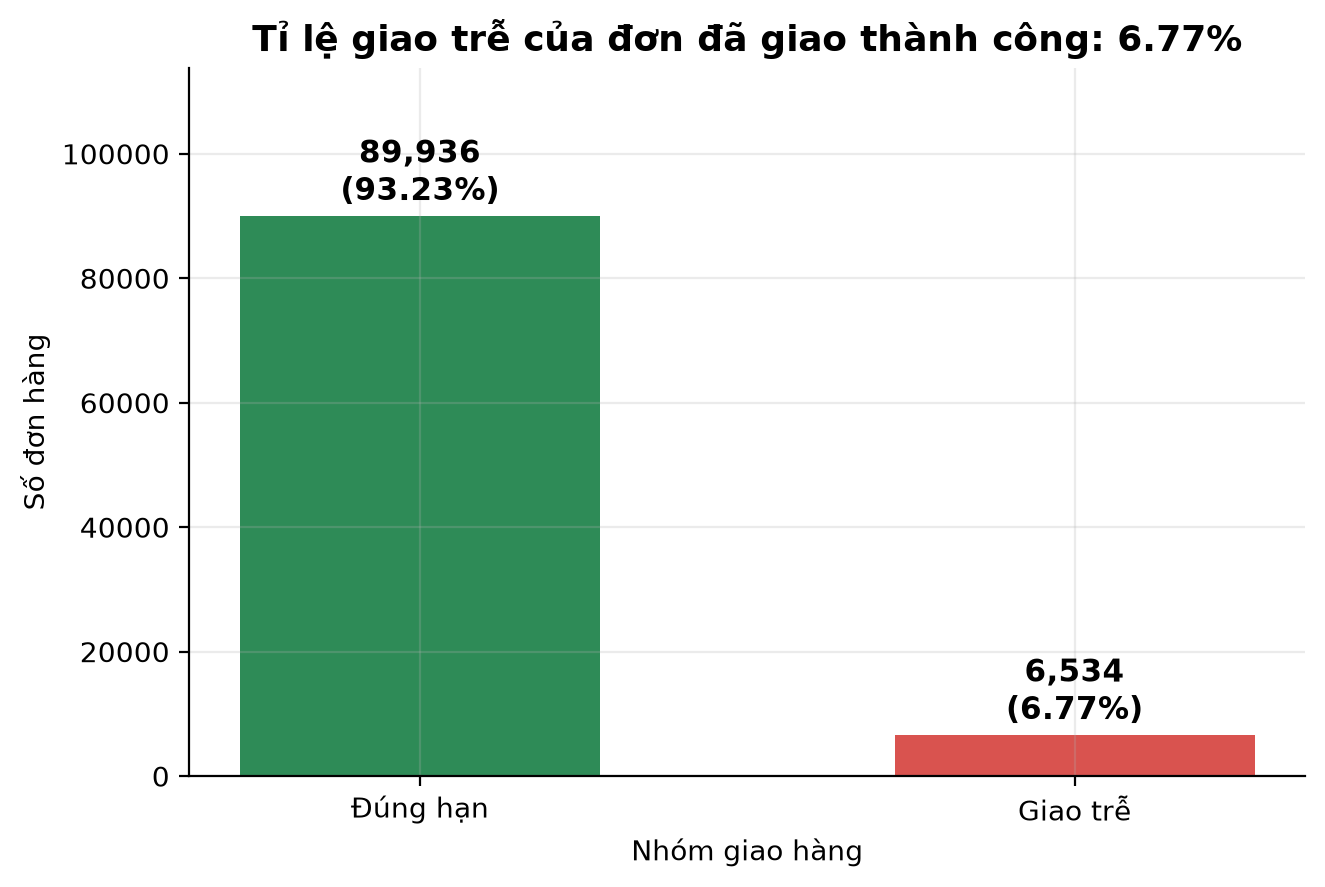

  -> đã lưu fig_01_ti_le_giao_tre.png


In [8]:
# --- Hình 1: tỉ lệ đơn đúng hạn vs giao trễ ------------------------
fig, ax = plt.subplots(figsize=(7.2, 4.6))
labels = ["Đúng hạn", "Giao trễ"]
values = [n_on_time, n_late]
bars = ax.bar(labels, values, color=[C_OK, C_LATE], width=0.55)
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width() / 2, v + n_eda * 0.01,
            f"{v:,}\n({v/n_eda:.2%})", ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.set_ylim(0, n_eda * 1.18)
ax.set_ylabel("Số đơn hàng")
ax.set_title(f"Tỉ lệ giao trễ của đơn đã giao thành công: {late_rate:.2%}")
ax.set_xlabel("Nhóm giao hàng")
savefig(fig, "fig_01_ti_le_giao_tre.png")

### 1.4. Phân phối thời gian giao hàng và điểm review

Các phân vị thời gian giao (ngày): {'P5': np.float64(3.0), 'P25': np.float64(6.8), 'P50': np.float64(10.2), 'P75': np.float64(15.7), 'P95': np.float64(29.3)}


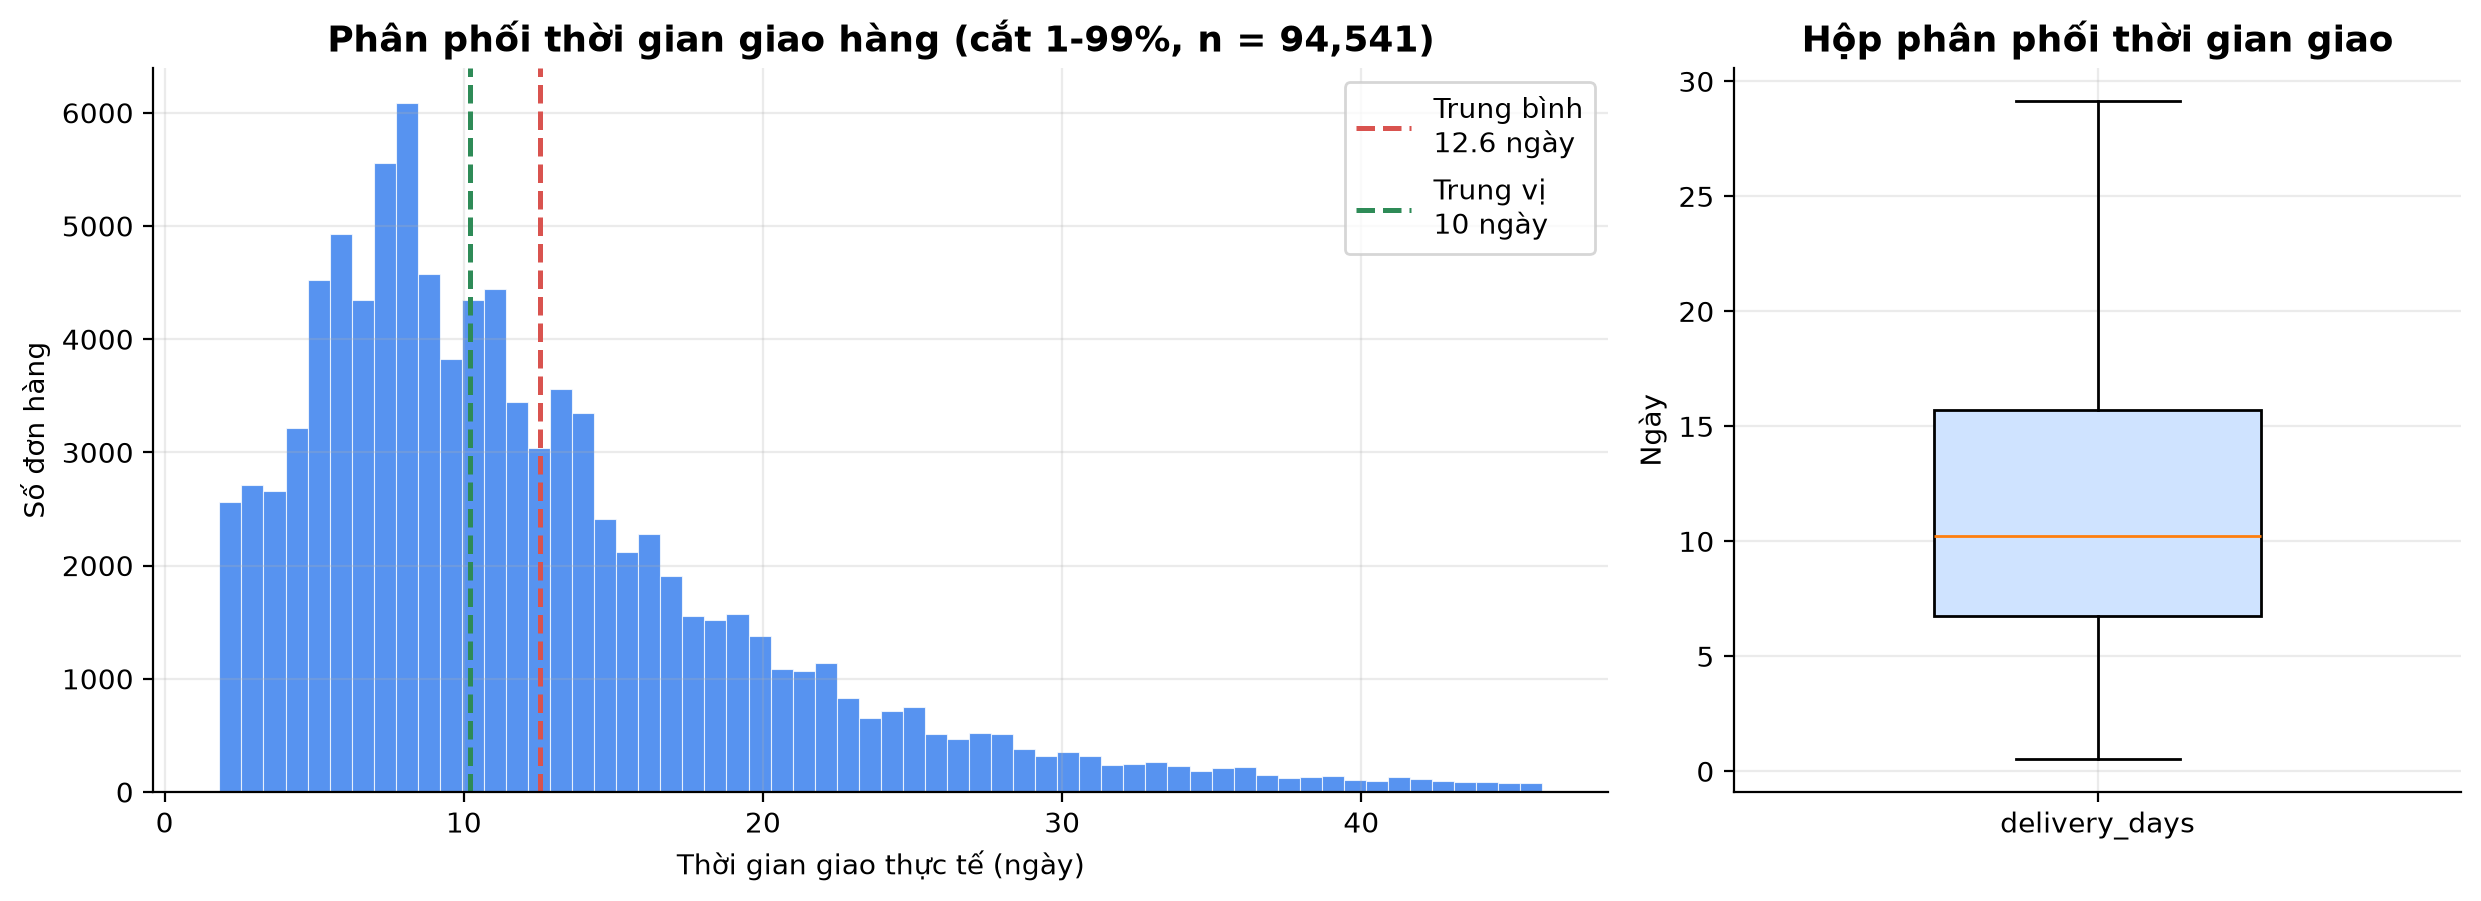

  -> đã lưu fig_02_phan_phoi_thoi_gian_giao.png


In [9]:
# --- Hình 2: phân phối thời gian giao thực tế ----------------------
d = eda["delivery_days"].dropna()
p1, p99 = d.quantile([0.01, 0.99])
clip = d[(d >= p1) & (d <= p99)]   # cắt 1% hai đuôi để trục đọc dễ

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6),
                         gridspec_kw={"width_ratios": [2, 1]})
ax = axes[0]
ax.hist(clip, bins=60, color=C_MAIN, alpha=0.75, edgecolor="white", linewidth=0.4)
for x, lab, col in [(d.mean(), f"Trung bình\n{d.mean():.1f} ngày", C_LATE),
                    (d.median(), f"Trung vị\n{d.median():.0f} ngày", C_OK)]:
    ax.axvline(x, color=col, linestyle="--", linewidth=1.8, label=lab)
ax.set_xlabel("Thời gian giao thực tế (ngày)")
ax.set_ylabel("Số đơn hàng")
ax.set_title(f"Phân phối thời gian giao hàng (cắt 1-99%, n = {len(clip):,})")
ax.legend()

ax = axes[1]
qs = [0.05, 0.25, 0.5, 0.75, 0.95]
box = ax.boxplot([d], tick_labels=["delivery_days"], patch_artist=True,
                 widths=0.45, showfliers=False)
box["boxes"][0].set_facecolor("#cfe3ff")
pct = {q: d.quantile(q) for q in qs}
ax.set_title("Hộp phân phối thời gian giao")
ax.set_ylabel("Ngày")
fig.tight_layout()
print("Các phân vị thời gian giao (ngày):",
      {f"P{int(q*100)}": round(v, 1) for q, v in pct.items()})
savefig(fig, "fig_02_phan_phoi_thoi_gian_giao.png")

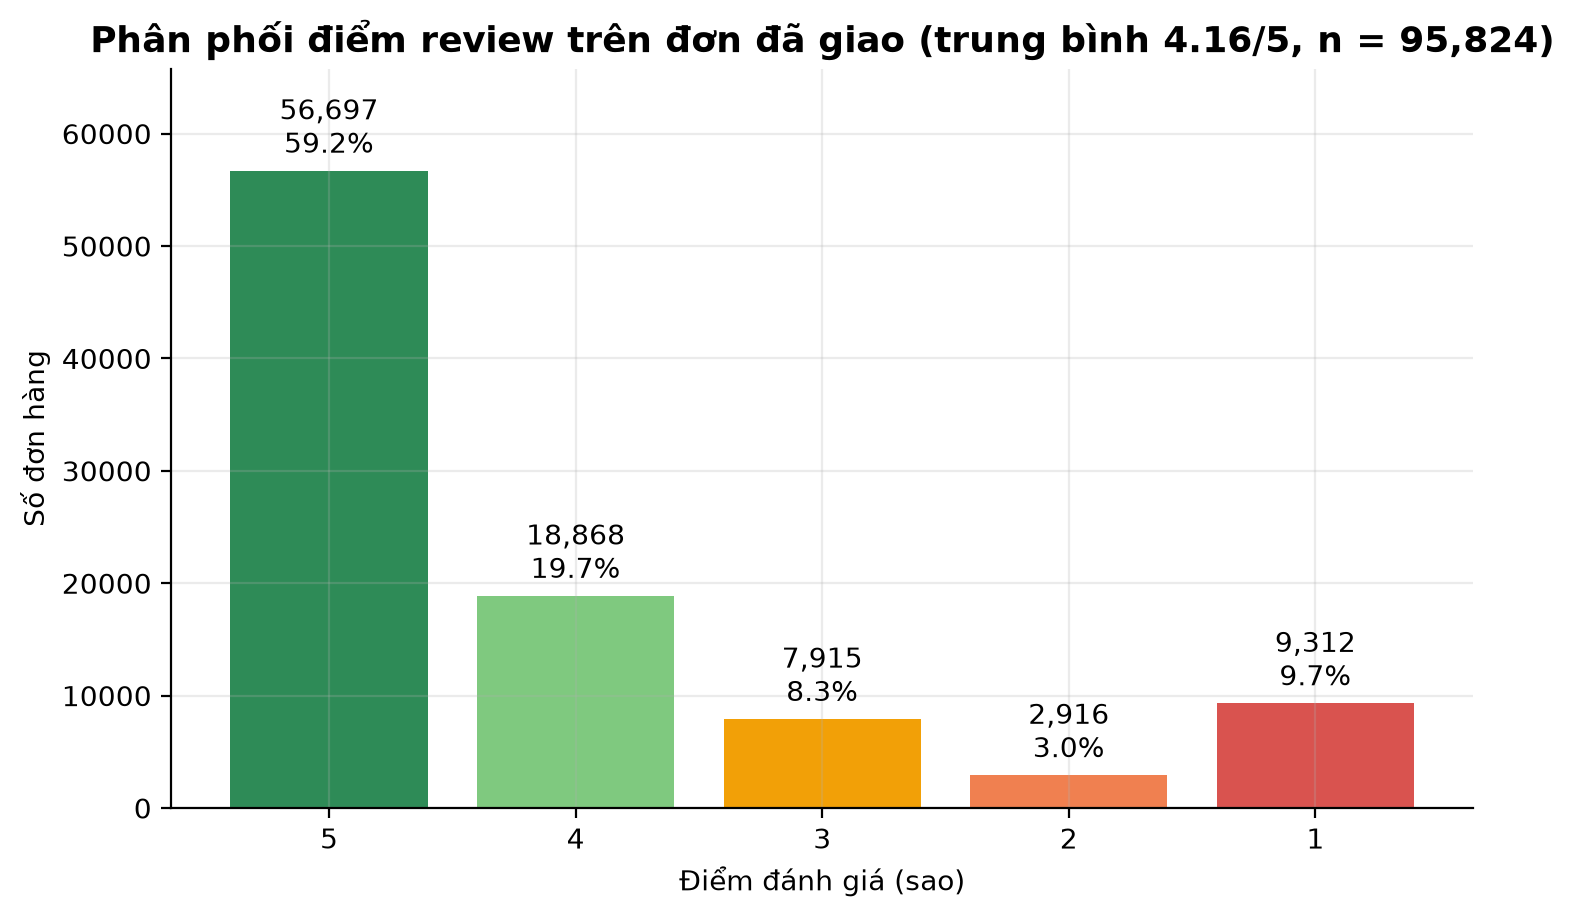

  -> đã lưu fig_03_phan_phoi_review_score.png
Review thấp (1-2 sao): 12,236 đơn = 12.77%
Review cao  (4-5 sao): 75,619 đơn = 78.91%


In [10]:
# --- Hình 3: phân phối review_score --------------------------------
rv = eda["review_score"].dropna()
order_share = rv.value_counts(normalize=True).reindex(range(5, 0, -1))
order_count = rv.value_counts().reindex(range(5, 0, -1))

fig, ax = plt.subplots(figsize=(8.4, 4.8))
colors = {5: C_OK, 4: "#7FC97F", 3: C_ACCENT, 2: "#F08050", 1: C_LATE}
idx = [str(i) for i in order_count.index]
bars = ax.bar(idx, order_count.values, color=[colors[i] for i in order_count.index])
for b, v in zip(bars, order_count.values):
    ax.text(b.get_x() + b.get_width() / 2, v + len(rv) * 0.008,
            f"{v:,}\n{v/len(rv):.1%}", ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, order_count.max() * 1.16)
ax.set_xlabel("Điểm đánh giá (sao)")
ax.set_ylabel("Số đơn hàng")
ax.set_title(f"Phân phối điểm review trên đơn đã giao (trung bình {rv.mean():.2f}/5, n = {len(rv):,})")
savefig(fig, "fig_03_phan_phoi_review_score.png")

n_low = int((rv <= 2).sum())
print(f"Review thấp (1-2 sao): {n_low:,} đơn = {n_low/len(rv):.2%}")
print(f"Review cao  (4-5 sao): {int((rv >= 4).sum()):,} đơn = {(rv >= 4).mean():.2%}")

### 1.5. Review theo nhóm giao đúng hạn vs giao trễ

Đây là giả thuyết trung tâm của đồ án: **giao trễ làm giảm điểm đánh giá**.
So sánh bằng trung bình + kiểm định Mann-Whitney U (phi tham số, không đòi hỏi phân phối chuẩn).

delay_days
Trễ 1-3 ngày     3.291
Trễ 4-7 ngày     2.106
Trễ 8-15 ngày    1.675
Trễ > 15 ngày    1.728
Name: review_score, dtype: float64


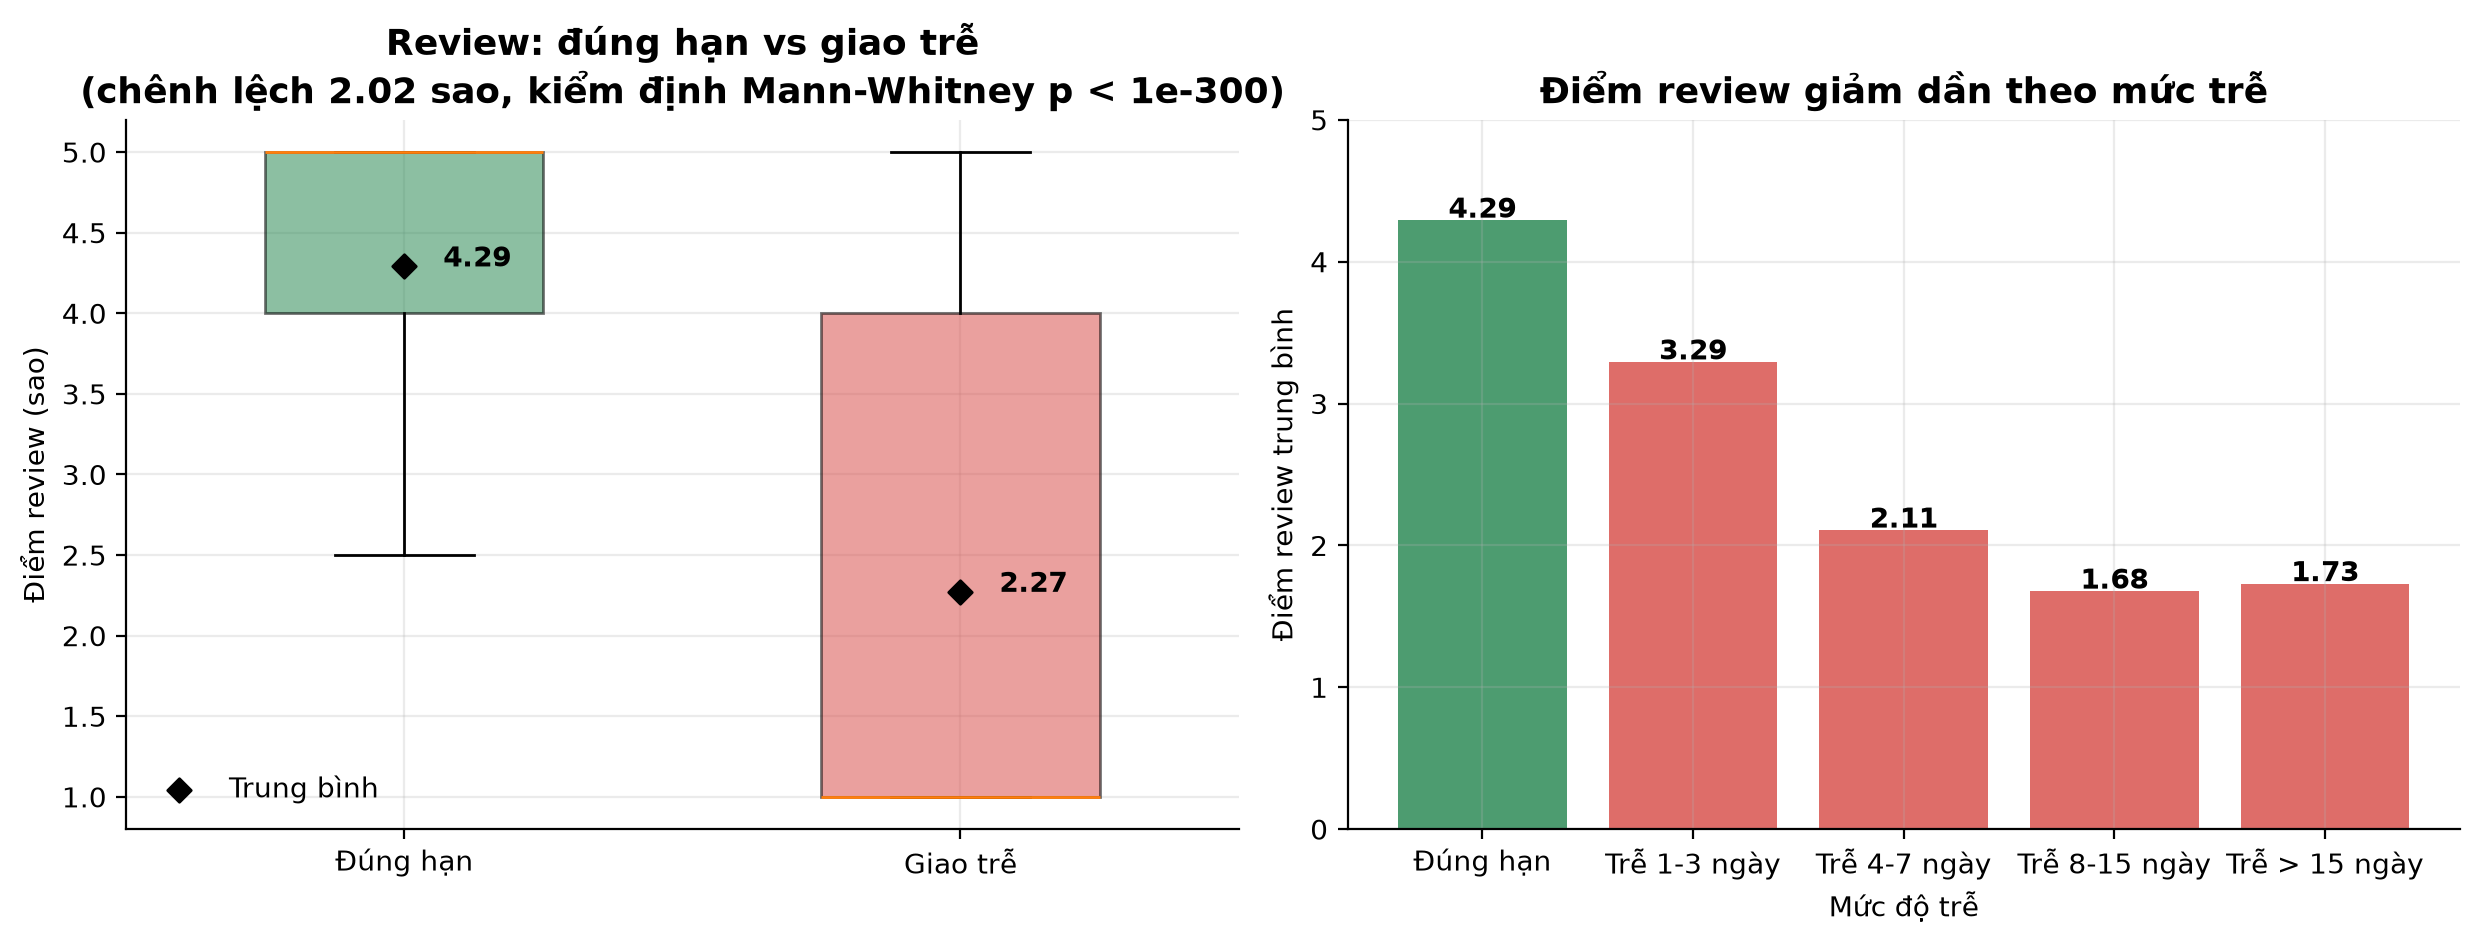

  -> đã lưu fig_04_review_dung_han_vs_giao_tre.png


In [11]:
# --- Hình 4: review_score theo nhóm on-time / late -----------------
sub = eda.dropna(subset=["review_score"])
g_ok = sub.loc[sub["on_time"], "review_score"]
g_late = sub.loc[~sub["on_time"], "review_score"]

# Mức trễ cũng được chia tổ để xem "trễ bao lâu thì mất bao nhiêu điểm"
late_bins = pd.cut(sub.loc[~sub["on_time"], "delay_days"],
                   bins=[0, 3, 7, 15, 10**6],
                   labels=["Trễ 1-3 ngày", "Trễ 4-7 ngày", "Trễ 8-15 ngày", "Trễ > 15 ngày"])
late_profile = sub.loc[~sub["on_time"]].groupby(late_bins, observed=True)["review_score"].mean()

u_stat, p_value = sps.mannwhitneyu(g_ok, g_late, alternative="greater")
# p-value underflow về 0 với mẫu ~95k -> ghi chú thích rõ ràng thay vì in 0.00e+00
p_text = "p < 1e-300" if p_value < 1e-300 else f"p = {p_value:.2e}"
diff = g_ok.mean() - g_late.mean()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
ax = axes[0]
box = ax.boxplot([g_ok, g_late], tick_labels=["Đúng hạn", "Giao trễ"],
                 patch_artist=True, widths=0.5, showfliers=False)
for patch, col in zip(box["boxes"], [C_OK, C_LATE]):
    patch.set_facecolor(col); patch.set_alpha(0.55)
means = [g_ok.mean(), g_late.mean()]
ax.scatter([1, 2], means, color="black", zorder=5, marker="D", label="Trung bình")
for i, m in enumerate(means, start=1):
    ax.annotate(f"{m:.2f}", (i, m), textcoords="offset points", xytext=(14, 0), fontweight="bold")
ax.set_ylabel("Điểm review (sao)")
ax.set_title(f"Review: đúng hạn vs giao trễ\n(chênh lệch {diff:.2f} sao, kiểm định Mann-Whitney {p_text})")
ax.legend(frameon=False)

ax = axes[1]
vals = pd.concat([pd.Series({"Đúng hạn": g_ok.mean()}), late_profile]).astype(float)
labels = [str(i) for i in vals.index]
cols = [C_OK] + [C_LATE] * (len(vals) - 1)
bars = ax.bar(labels, vals.values, color=cols, alpha=0.85)
for b, v in zip(bars, vals.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center", fontweight="bold")
ax.set_ylim(0, 5)
ax.set_ylabel("Điểm review trung bình")
ax.set_xlabel("Mức độ trễ")
ax.set_title("Điểm review giảm dần theo mức trễ")
fig.tight_layout()
print(late_profile.round(3))
savefig(fig, "fig_04_review_dung_han_vs_giao_tre.png")

### 1.6. Phí ship theo bang / khu vực và mối liên hệ với review

Brazil có 27 bang (`customer_state`); 4 bang đông đơn nhất thường chiếm >70% giao dịch,
nên phần còn lại được nhóm theo **khu vực** để so sánh công bằng hơn.

In [12]:
# --------------------------------------------------------------------
# 7. Gán khu vực Brazil cho từng bang
# --------------------------------------------------------------------
REGION = {
    "AC": "Norte", "AM": "Norte", "AP": "Norte", "PA": "Norte",
    "RO": "Norte", "RR": "Norte", "TO": "Norte",
    "AL": "Nordeste", "BA": "Nordeste", "CE": "Nordeste", "MA": "Nordeste",
    "PB": "Nordeste", "PE": "Nordeste", "PI": "Nordeste", "RN": "Nordeste",
    "SE": "Nordeste",
    "DF": "Centro-Oeste", "GO": "Centro-Oeste", "MS": "Centro-Oeste", "MT": "Centro-Oeste",
    "ES": "Sudeste", "MG": "Sudeste", "RJ": "Sudeste", "SP": "Sudeste",
    "PR": "Sul", "RS": "Sul", "SC": "Sul",
}
eda["region"] = eda["customer_state"].map(REGION).fillna("Khác")

state_stats = (
    eda.groupby("customer_state")
    .agg(n_orders=("order_id", "size"),
         avg_freight=("freight_value", "mean"),
         median_freight=("freight_value", "median"),
         avg_price=("price", "mean"),
         avg_review=("review_score", "mean"),
         late_rate=("is_late", "mean"))
    .sort_values("n_orders", ascending=False)
)
# Tỉ trọng phí ship của bang so với toàn bộ doanh thu vận chuyển
state_stats["freight_share"] = eda.groupby("customer_state")["freight_value"].sum() / eda["freight_value"].sum()
print("Top 12 bang theo số đơn:")
print(state_stats.head(12).round(3))
state_stats.round(4).to_csv(FIG_DIR.parent / "state_delivery_stats.csv")

Top 12 bang theo số đơn:
                n_orders  avg_freight  median_freight  avg_price  avg_review  late_rate  freight_share
customer_state                                                                                        
SP                 40494       17.335          13.610    125.119       4.247      0.045          0.319
RJ                 12350       23.947          17.980    142.482       3.965      0.121          0.135
MG                 11354       23.464          18.185    136.734       4.192      0.046          0.121
RS                  5344       24.805          18.230    136.362       4.186      0.061          0.060
PR                  4923       23.491          17.880    135.296       4.240      0.040          0.053
SC                  3546       24.849          18.230    142.981       4.133      0.082          0.040
BA                  3256       29.961          22.070    151.592       3.930      0.122          0.044
DF                  2080       23.858          1

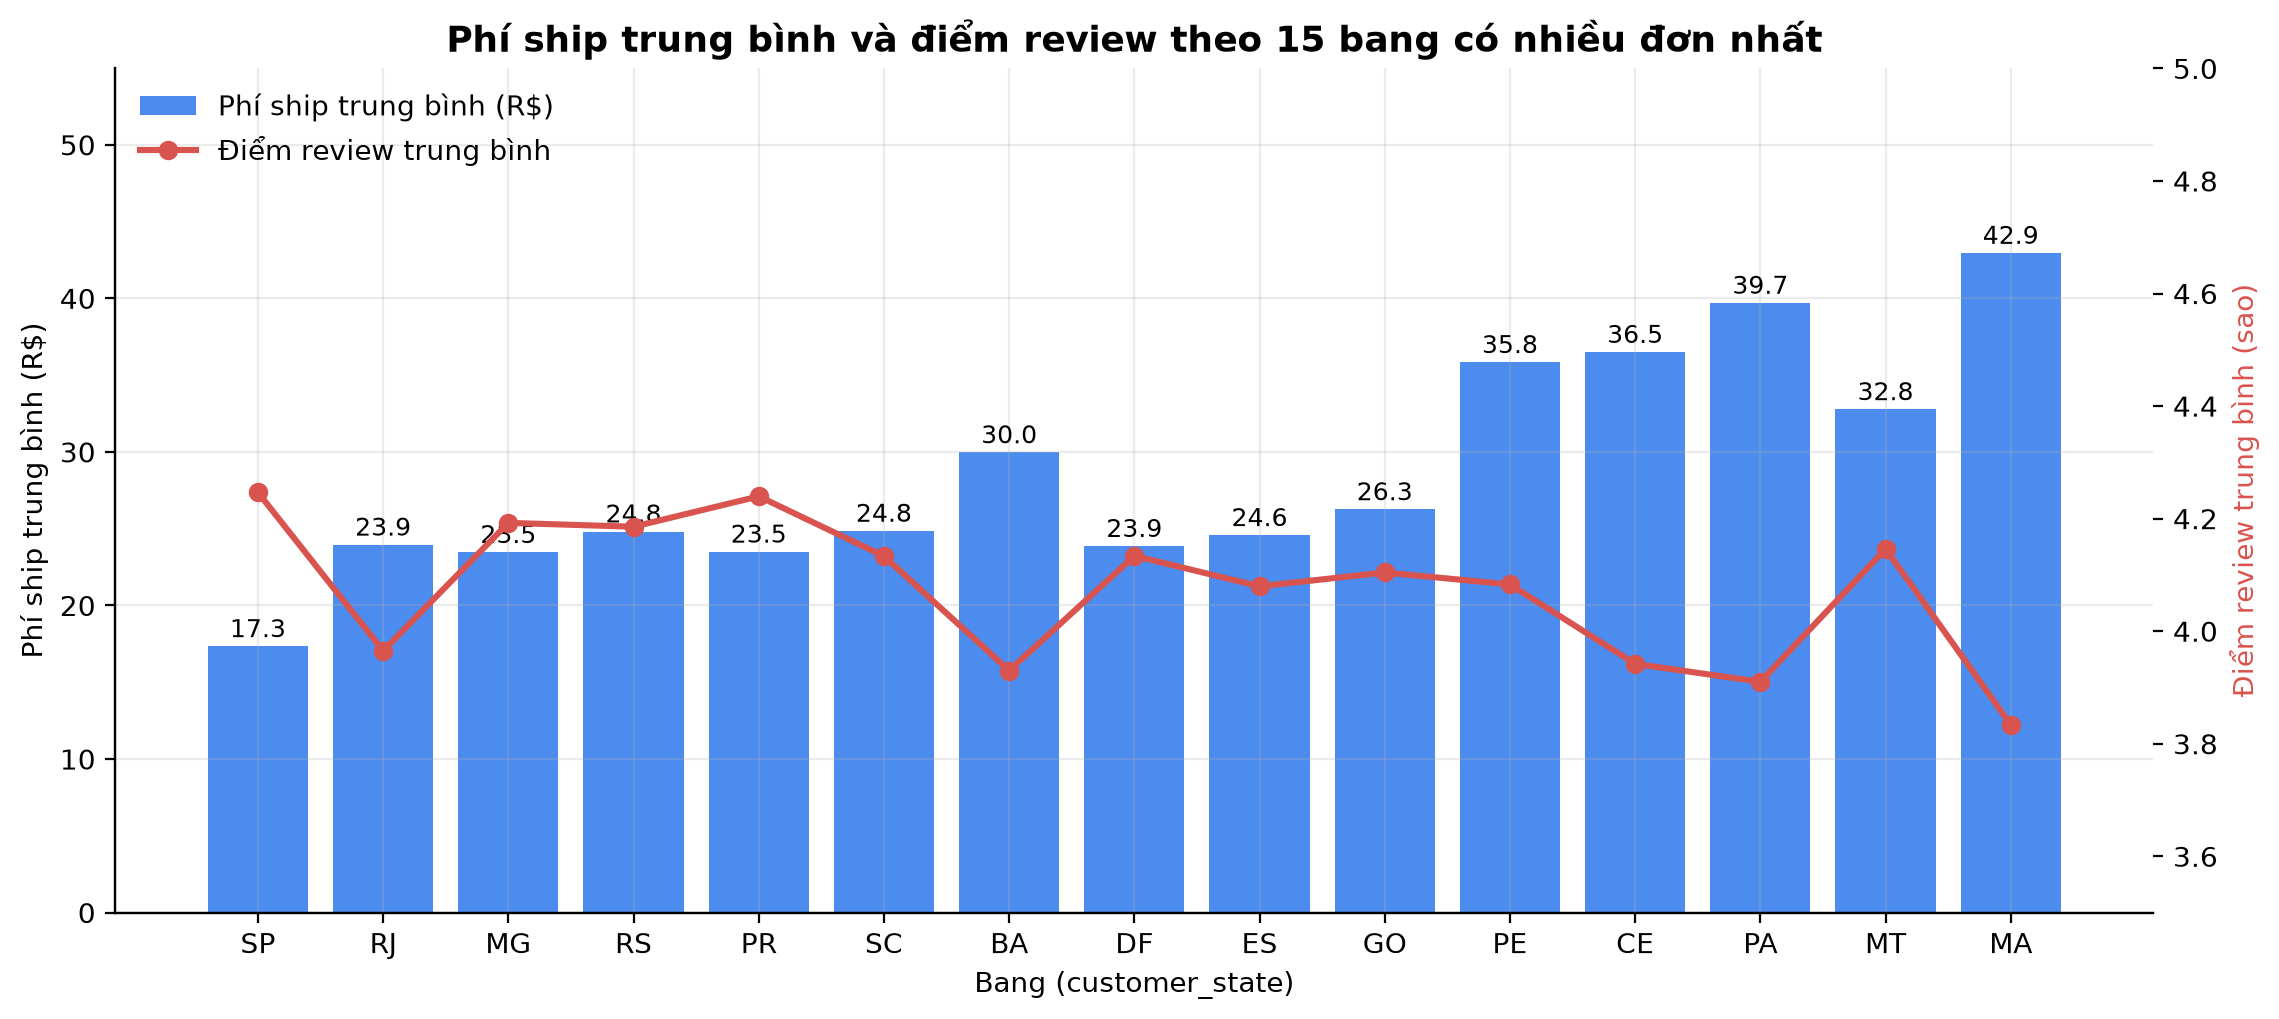

  -> đã lưu fig_05_freight_theo_bang.png


In [13]:
# --- Hình 5: phí ship trung bình theo bang + điểm review -----------
top = state_stats.head(15)
fig, ax = plt.subplots(figsize=(11.5, 5.2))
x = np.arange(len(top))
bars = ax.bar(x, top["avg_freight"], color=C_MAIN, alpha=0.8, label="Phí ship trung bình (R$)")
ax.set_xlabel("Bang (customer_state)")
ax.set_ylabel("Phí ship trung bình (R$)")
ax.set_ylim(0, top["avg_freight"].max() * 1.28)
ax.set_xticks(x, top.index)
for b, v in zip(bars, top["avg_freight"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.6, f"{v:.1f}", ha="center", fontsize=9)

ax2 = ax.twinx()
ax2.plot(x, top["avg_review"], color=C_LATE, marker="o", linewidth=2.2,
         label="Điểm review trung bình")
ax2.set_ylabel("Điểm review trung bình (sao)", color=C_LATE)
ax2.set_ylim(3.5, 5.0)
ax2.grid(False)
ax.set_title("Phí ship trung bình và điểm review theo 15 bang có nhiều đơn nhất")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", frameon=False)
fig.tight_layout()
savefig(fig, "fig_05_freight_theo_bang.png")

              n_orders  avg_freight  avg_price  avg_delivery_days  late_rate  avg_review
region                                                                                  
Sudeste          66193       19.838    130.638             10.752      0.061       4.180
Sul              13813       24.348    137.681             14.032      0.059       4.191
Nordeste          9044       35.986    165.533             20.005      0.127       3.970
Centro-Oeste      5624       26.488    150.597             15.018      0.065       4.129
Norte             1796       41.350    182.113             22.592      0.086       4.029
Tương quan phí ship ~ review: Pearson r=-0.090 (p=2.4e-171), Spearman rho=-0.089
Tỉ lệ phí ship / giá hàng trung bình: 0.308 (trung vị 0.224)
                  avg_review      n    mid
bin_ship                                  
(-0.001, 10.96]        4.338  12117   8.29
(10.96, 13.84]         4.293  11857  12.70
(13.84, 15.3]          4.196  12061  14.84
(15.3, 17.16]       

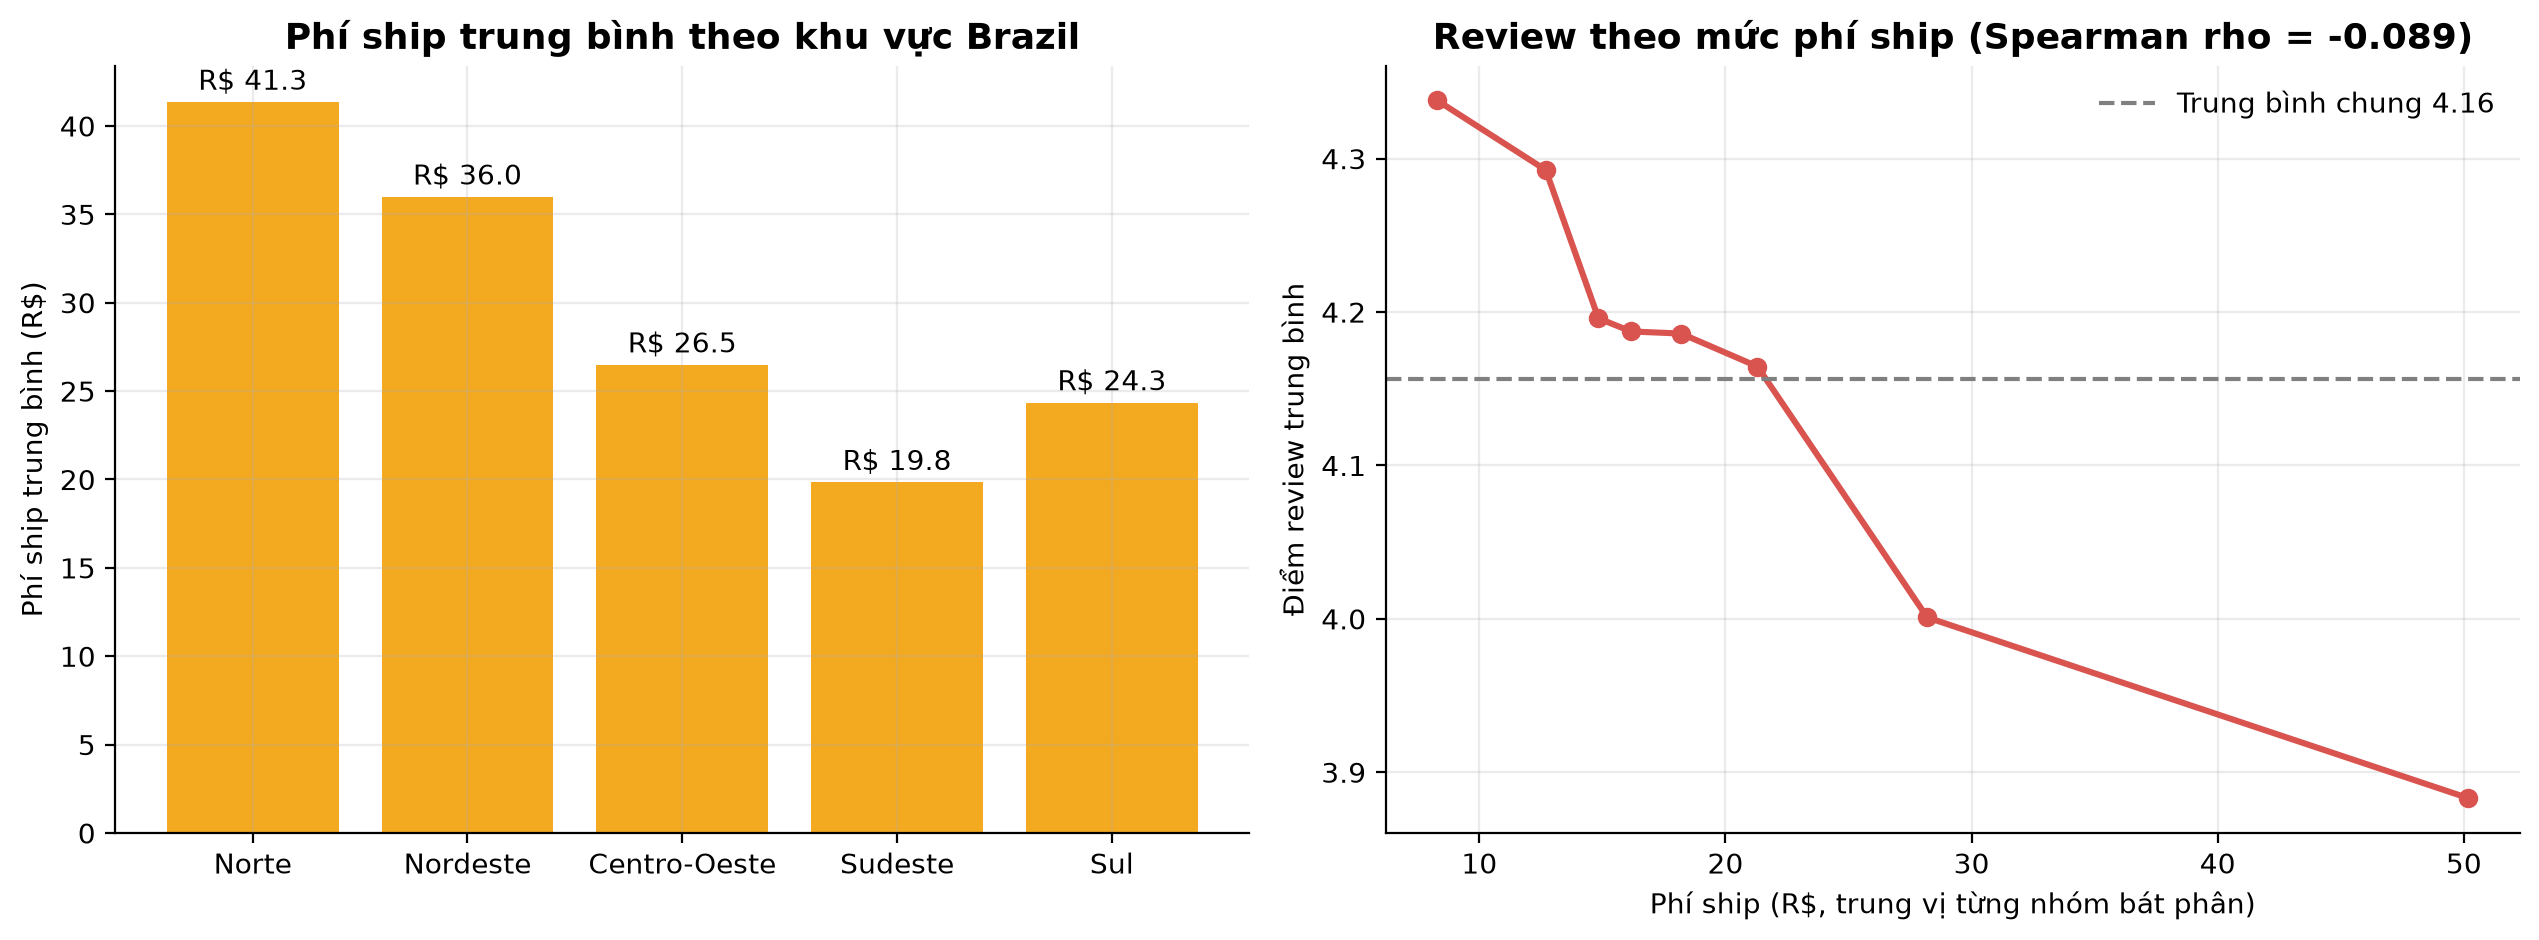

  -> đã lưu fig_06_freight_vs_review.png


In [14]:
# --- Hình 6: phí ship theo khu vực + tương quan ship/review --------
region_stats = (
    eda.groupby("region")
    .agg(n_orders=("order_id", "size"),
         avg_freight=("freight_value", "mean"),
         avg_price=("price", "mean"),
         avg_delivery_days=("delivery_days", "mean"),
         late_rate=("is_late", "mean"),
         avg_review=("review_score", "mean"))
    .sort_values("n_orders", ascending=False)
)
print(region_stats.round(3))

fr = eda.dropna(subset=["freight_value", "review_score"])
pearson_r, pearson_p = sps.pearsonr(fr["freight_value"], fr["review_score"])
spearman_r, spearman_p = sps.spearmanr(fr["freight_value"], fr["review_score"])
ratio = (fr["freight_value"] / fr["price"].replace(0, np.nan)).dropna()
print(f"Tương quan phí ship ~ review: Pearson r={pearson_r:.3f} (p={pearson_p:.1e}), "
      f"Spearman rho={spearman_r:.3f}")
print(f"Tỉ lệ phí ship / giá hàng trung bình: {ratio.mean():.3f} (trung vị {ratio.median():.3f})")

fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.8))
ax = axes[0]
order = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
order = [r for r in order if r in region_stats.index]
bars = ax.bar(order, region_stats.loc[order, "avg_freight"], color=C_ACCENT, alpha=0.9)
for b, v in zip(bars, region_stats.loc[order, "avg_freight"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.7, f"R$ {v:.1f}", ha="center", fontsize=10)
ax.set_ylabel("Phí ship trung bình (R$)")
ax.set_title("Phí ship trung bình theo khu vực Brazil")

ax = axes[1]
fr = fr.assign(bin_ship=pd.qcut(fr["freight_value"], q=8, duplicates="drop"))
ship_profile = fr.groupby("bin_ship", observed=True).agg(
    avg_review=("review_score", "mean"), n=("review_score", "size"),
    mid=("freight_value", "median"))
ax.plot(ship_profile["mid"], ship_profile["avg_review"], marker="o", color=C_LATE, linewidth=2.2)
ax.axhline(eda["review_score"].mean(), color="grey", linestyle="--",
           label=f"Trung bình chung {eda['review_score'].mean():.2f}")
ax.set_xlabel("Phí ship (R$, trung vị từng nhóm bát phân)")
ax.set_ylabel("Điểm review trung bình")
ax.set_title(f"Review theo mức phí ship (Spearman rho = {spearman_r:.3f})")
ax.legend(frameon=False)
fig.tight_layout()
print(ship_profile.round(3))
savefig(fig, "fig_06_freight_vs_review.png")

### 1.7. Ba yếu tố nào thực sự đẩy điểm review xuống?

So sánh đồng thời ba biến liên tục với `review_score` bằng hệ số **Spearman** (hạng,
phi tham số) trên cùng một tập đơn có đủ cả review, ship, thời gian giao.

                 avg_review    mid      n
delivery_days                            
(0.529, 4.75]         4.456   3.25  11980
(4.75, 6.76]          4.384   5.86  12022
(6.76, 8.24]          4.373   7.43  11944
(8.24, 10.21]         4.326   9.20  12041
(10.21, 12.6]         4.281  11.31  11923
(12.6, 15.66]         4.235  13.99  11960
(15.66, 21.15]        4.100  18.01  11979
(21.15, 208.35]       3.094  27.18  11975
            avg_review      n
delay_days                   
<-8              4.317  70929
-7..-4           4.226  12529
-3..0            4.112   5985
1-3              3.291   1852
4-7              2.106   1748
>7               1.698   2781
Kiểm định Spearman: thời gian giao rho=-0.235 (p=0.0e+00), mức trễ rho=-0.176 (p=0.0e+00), phí ship rho=-0.089


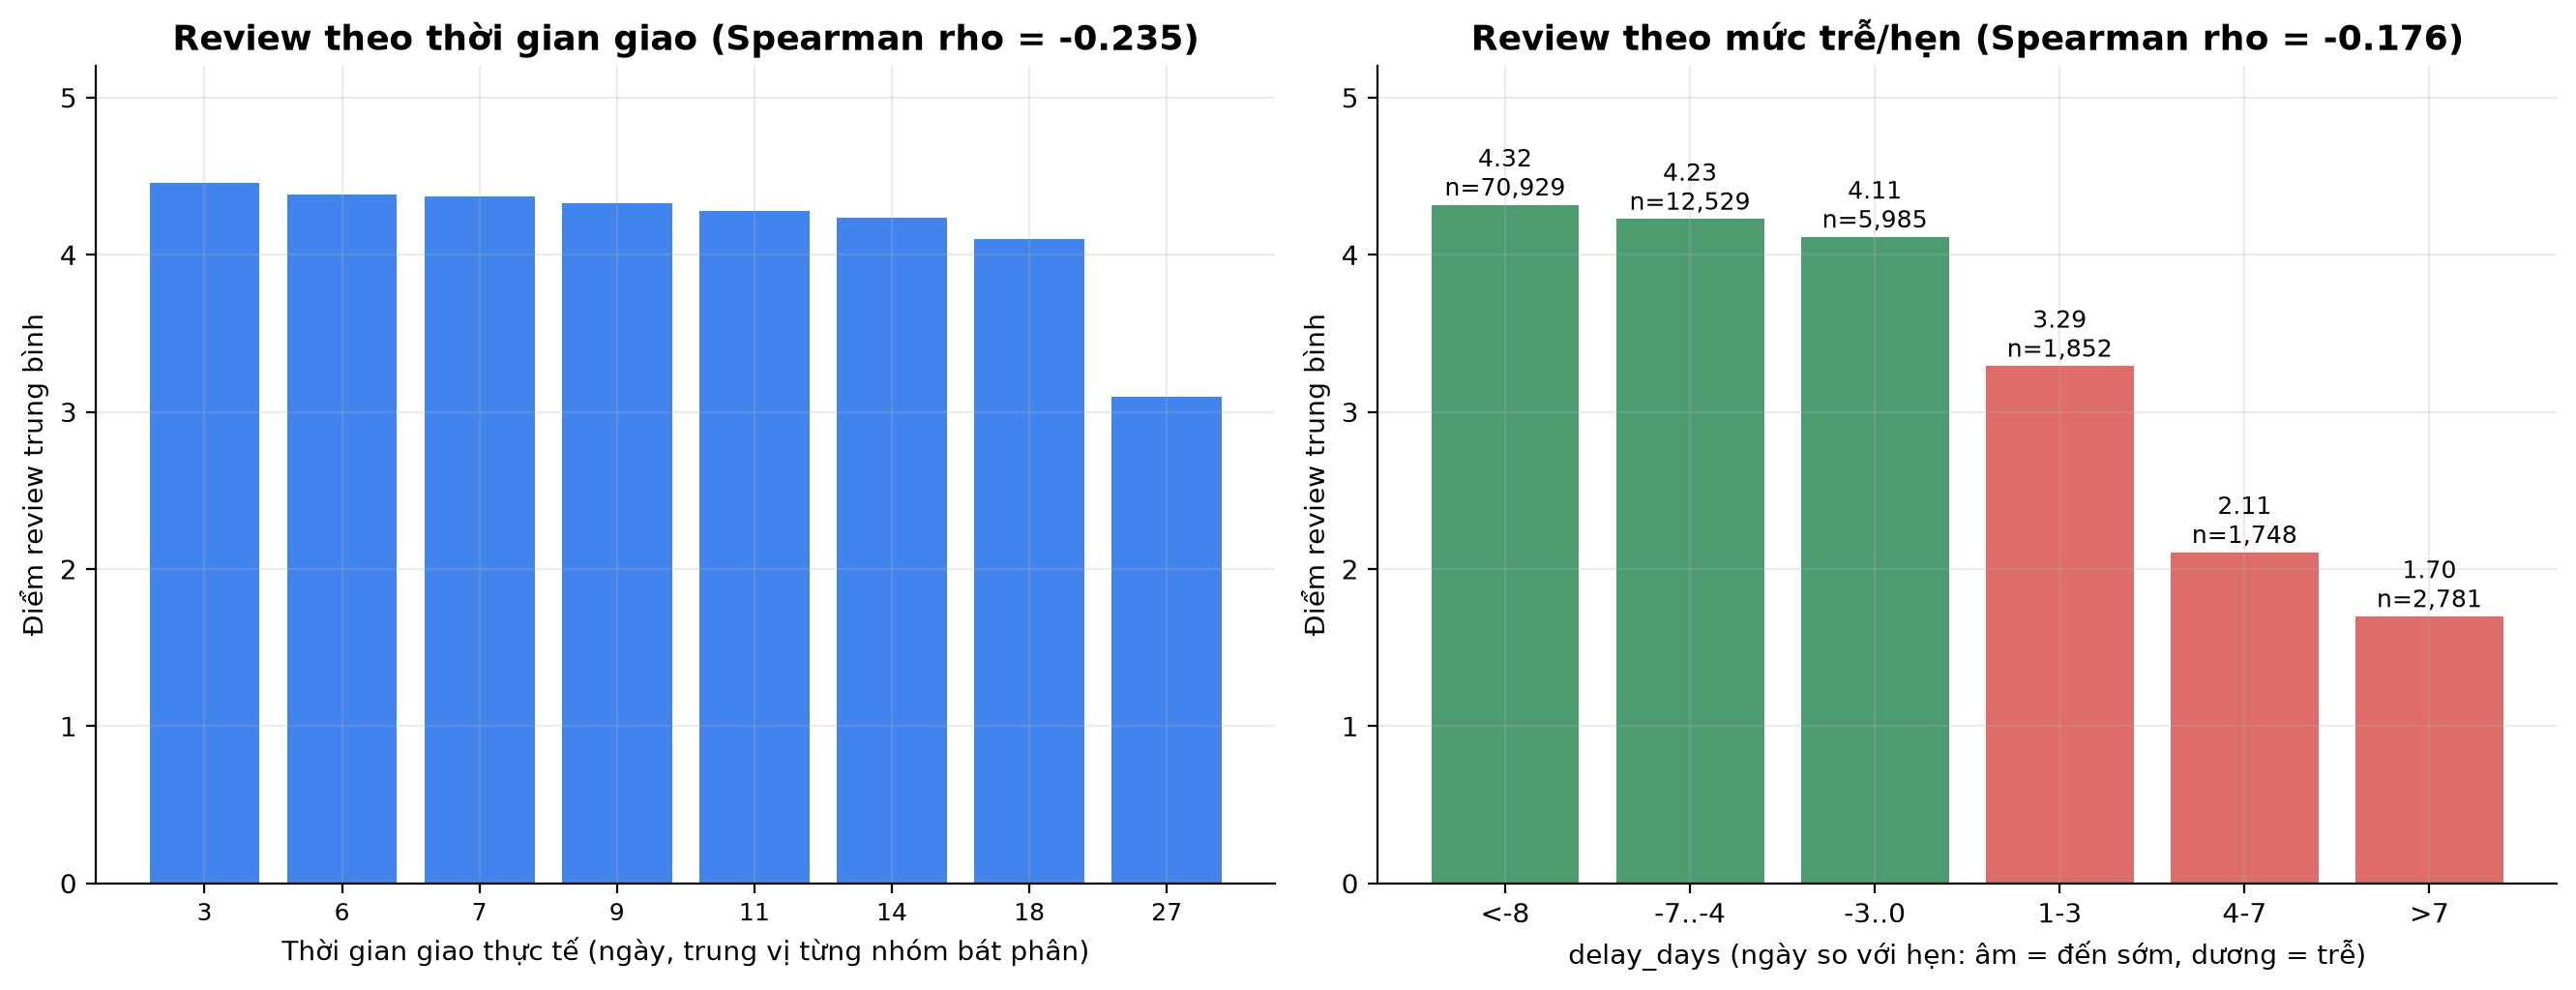

  -> đã lưu fig_07_review_theo_thoi_gian_va_tre.png


In [15]:
# --- Hình 7: review theo thời gian giao & theo mức trễ --------------
s = eda.dropna(subset=["review_score", "delivery_days", "delay_days"])
rho_time, p_time = sps.spearmanr(s["delivery_days"], s["review_score"])
rho_delay, p_delay = sps.spearmanr(s["delay_days"], s["review_score"])
rho_ship, _ = sps.spearmanr(
    s["freight_value"], s["review_score"], nan_policy="omit")

day_bins = pd.qcut(s["delivery_days"], q=8, duplicates="drop")
delay_cat = pd.cut(s["delay_days"],
                   bins=[-10**6, -8, -4, 0, 3, 7, 10**6],
                   labels=["<-8", "-7..-4", "-3..0", "1-3", "4-7", ">7"])

fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.0), constrained_layout=True)
ax = axes[0]
time_profile = s.groupby(day_bins, observed=True).agg(
    avg_review=("review_score", "mean"), mid=("delivery_days", "median"),
    n=("review_score", "size"))
ax.bar(range(len(time_profile)), time_profile["avg_review"], color=C_MAIN, alpha=0.85)
ax.set_xticks(range(len(time_profile)), [f"{m:.0f}" for m in time_profile["mid"]], fontsize=9)
ax.set_ylim(0, 5.2)
ax.set_xlabel("Thời gian giao thực tế (ngày, trung vị từng nhóm bát phân)")
ax.set_ylabel("Điểm review trung bình")
ax.set_title(f"Review theo thời gian giao (Spearman rho = {rho_time:.3f})")

ax = axes[1]
delay_profile = s.groupby(delay_cat, observed=True).agg(
    avg_review=("review_score", "mean"), n=("review_score", "size"))
cols = [C_OK] * 3 + [C_LATE] * 3
bars = ax.bar([str(i) for i in delay_profile.index], delay_profile["avg_review"],
              color=cols, alpha=0.85)
for b, v, nn in zip(bars, delay_profile["avg_review"], delay_profile["n"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.06,
            f"{v:.2f}\nn={nn:,}", ha="center", fontsize=9)
ax.set_ylim(0, 5.2)
ax.set_ylabel("Điểm review trung bình")
ax.set_xlabel("delay_days (ngày so với hẹn: âm = đến sớm, dương = trễ)")
ax.set_title(f"Review theo mức trễ/hẹn (Spearman rho = {rho_delay:.3f})")
print(time_profile.round(3))
print(delay_profile.round(3))
print(f"Kiểm định Spearman: thời gian giao rho={rho_time:.3f} (p={p_time:.1e}), "
      f"mức trễ rho={rho_delay:.3f} (p={p_delay:.1e}), phí ship rho={rho_ship:.3f}")
savefig(fig, "fig_07_review_theo_thoi_gian_va_tre.png")

## Nhiệm vụ 2 - Đặc trưng trải nghiệm theo khách hàng

Gom nhóm toàn bộ đơn đã giao theo `customer_unique_id` và tính 6 đặc trưng trải nghiệm:

| Đặc trưng | Công thức |
|---|---|
| `avg_review_score` | Trung bình `review_score` của các đơn có review |
| `late_delivery_rate` | Trung bình `is_late` (tỉ lệ đơn giao trễ) |
| `avg_delivery_days` | Trung bình `delivery_days` |
| `avg_freight_value` | Trung bình `freight_value` |
| `freight_to_price_ratio` | Σ`freight_value` / Σ`price` |
| `low_review_count` | Số đơn có `review_score` ≤ 2 (1-2 sao) |

Kèm hai cột bối cảnh `n_orders`, `n_reviews` (cần thiết cho bước phân cụm sau này,
vì một khách 1 đơn và một khách 10 đơn không có cùng độ tin cậy dữ liệu).

In [16]:
# --------------------------------------------------------------------
# 8. Bộ cờ mức đơn hàng
# --------------------------------------------------------------------
eda["has_review"] = eda["review_score"].notna().astype(int)
eda["is_low_review"] = (eda["review_score"] <= 2).astype(int)  # NaN <= 2 đã cho False

# freight_to_price_ratio cần cộng tổng trước khi chia, tránh khách nhiều đơn bị lệch
grouped = eda.groupby("customer_unique_id", dropna=True)
feats = grouped.agg(
    n_orders=("order_id", "size"),
    n_reviews=("has_review", "sum"),
    avg_review_score=("review_score", "mean"),
    late_delivery_rate=("is_late", "mean"),
    avg_delivery_days=("delivery_days", "mean"),
    avg_freight_value=("freight_value", "mean"),
    low_review_count=("is_low_review", "sum"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
).reset_index()

feats["freight_to_price_ratio"] = feats["total_freight"] / feats["total_price"].replace(0, np.nan)
feats = feats.drop(columns=["total_price", "total_freight"])

for c in ["avg_review_score", "late_delivery_rate", "avg_delivery_days", "avg_freight_value"]:
    feats[c] = feats[c].round(4)
feats["freight_to_price_ratio"] = feats["freight_to_price_ratio"].round(4)
feats["low_review_count"] = feats["low_review_count"].astype(int)

# Sắp xếp cột theo đúng thứ tự yêu cầu đề bài
feature_cols = ["avg_review_score", "late_delivery_rate", "avg_delivery_days",
                "avg_freight_value", "freight_to_price_ratio", "low_review_count"]
experience = feats[["customer_unique_id", "n_orders", "n_reviews"] + feature_cols]

print(f"Số khách hàng (customer_unique_id) : {len(experience):,}")
print(f"Khách có ít nhất 1 review          : {experience['n_reviews'].gt(0).sum():,} "
      f"({experience['n_reviews'].gt(0).mean():.2%})")
print(f"Khách nhiều đơn (n_orders > 1)      : {experience['n_orders'].gt(1).sum():,} "
      f"({experience['n_orders'].gt(1).mean():.2%})")
print()
print(experience.describe().round(4).T)

Số khách hàng (customer_unique_id) : 93,350
Khách có ít nhất 1 review          : 92,747 (99.35%)
Khách nhiều đơn (n_orders > 1)      : 2,801 (3.00%)

                          count     mean      std   min     25%      50%      75%        max
n_orders                93350.0   1.0334   0.2091  1.00   1.000   1.0000   1.0000    15.0000
n_reviews               93350.0   1.0265   0.2236  0.00   1.000   1.0000   1.0000    15.0000
avg_review_score        92747.0   4.1536   1.2802  1.00   4.000   5.0000   5.0000     5.0000
late_delivery_rate      93350.0   0.0681   0.2505  0.00   0.000   0.0000   0.0000     1.0000
avg_delivery_days       93350.0  12.5675   9.5462  0.53   6.790  10.2300  15.7200   209.6300
avg_freight_value       93350.0  22.7798  21.4605  0.00  13.880  17.2400  24.1100  1794.9600
freight_to_price_ratio  93350.0   0.3064   0.3088  0.00   0.132   0.2243   0.3783    21.4471
low_review_count        93350.0   0.1311   0.3425  0.00   0.000   0.0000   0.0000     3.0000


In [17]:
# --------------------------------------------------------------------
# 9. Xuất experience_features.csv
# --------------------------------------------------------------------
out_csv = Path.cwd() / "experience_features.csv"
experience.to_csv(out_csv, index=False, encoding="utf-8")
print("Đã ghi:", out_csv, f"({len(experience):,} dòng x {experience.shape[1]} cột)")
print()
print("8 dòng đầu của experience_features.csv:")
print(experience.head(8).to_string(index=False))

Đã ghi: C:\Users\Admin\Downloads\ktdl\experience_features.csv (93,350 dòng x 9 cột)

8 dòng đầu của experience_features.csv:
              customer_unique_id  n_orders  n_reviews  avg_review_score  late_delivery_rate  avg_delivery_days  avg_freight_value  freight_to_price_ratio  low_review_count
0000366f3b9a7992bf8c76cfdf3221e2         1          1               5.0                 0.0               6.41              12.00                  0.0924                 0
0000b849f77a49e4a4ce2b2a4ca5be3f         1          1               4.0                 0.0               3.29               8.29                  0.4386                 0
0000f46a3911fa3c0805444483337064         1          1               3.0                 0.0              25.73              17.22                  0.2496                 0
0000f6ccb0745a6a4b88665a16c9f078         1          1               4.0                 0.0              20.04              17.63                  0.6783                 0
0004aac84e0df4d

Tương quan giữa các đặc trưng (Spearman, chỉ khách có review):
                        avg_review_score  late_delivery_rate  avg_delivery_days  avg_freight_value  freight_to_price_ratio  low_review_count
avg_review_score                   1.000              -0.301             -0.213             -0.121                  -0.047            -0.697
late_delivery_rate                -0.301               1.000              0.441              0.089                   0.008             0.356
avg_delivery_days                 -0.213               0.441              1.000              0.377                   0.160             0.202
avg_freight_value                 -0.121               0.089              0.377              1.000                   0.167             0.144
freight_to_price_ratio            -0.047               0.008              0.160              0.167                   1.000             0.020
low_review_count                  -0.697               0.356              0.202            

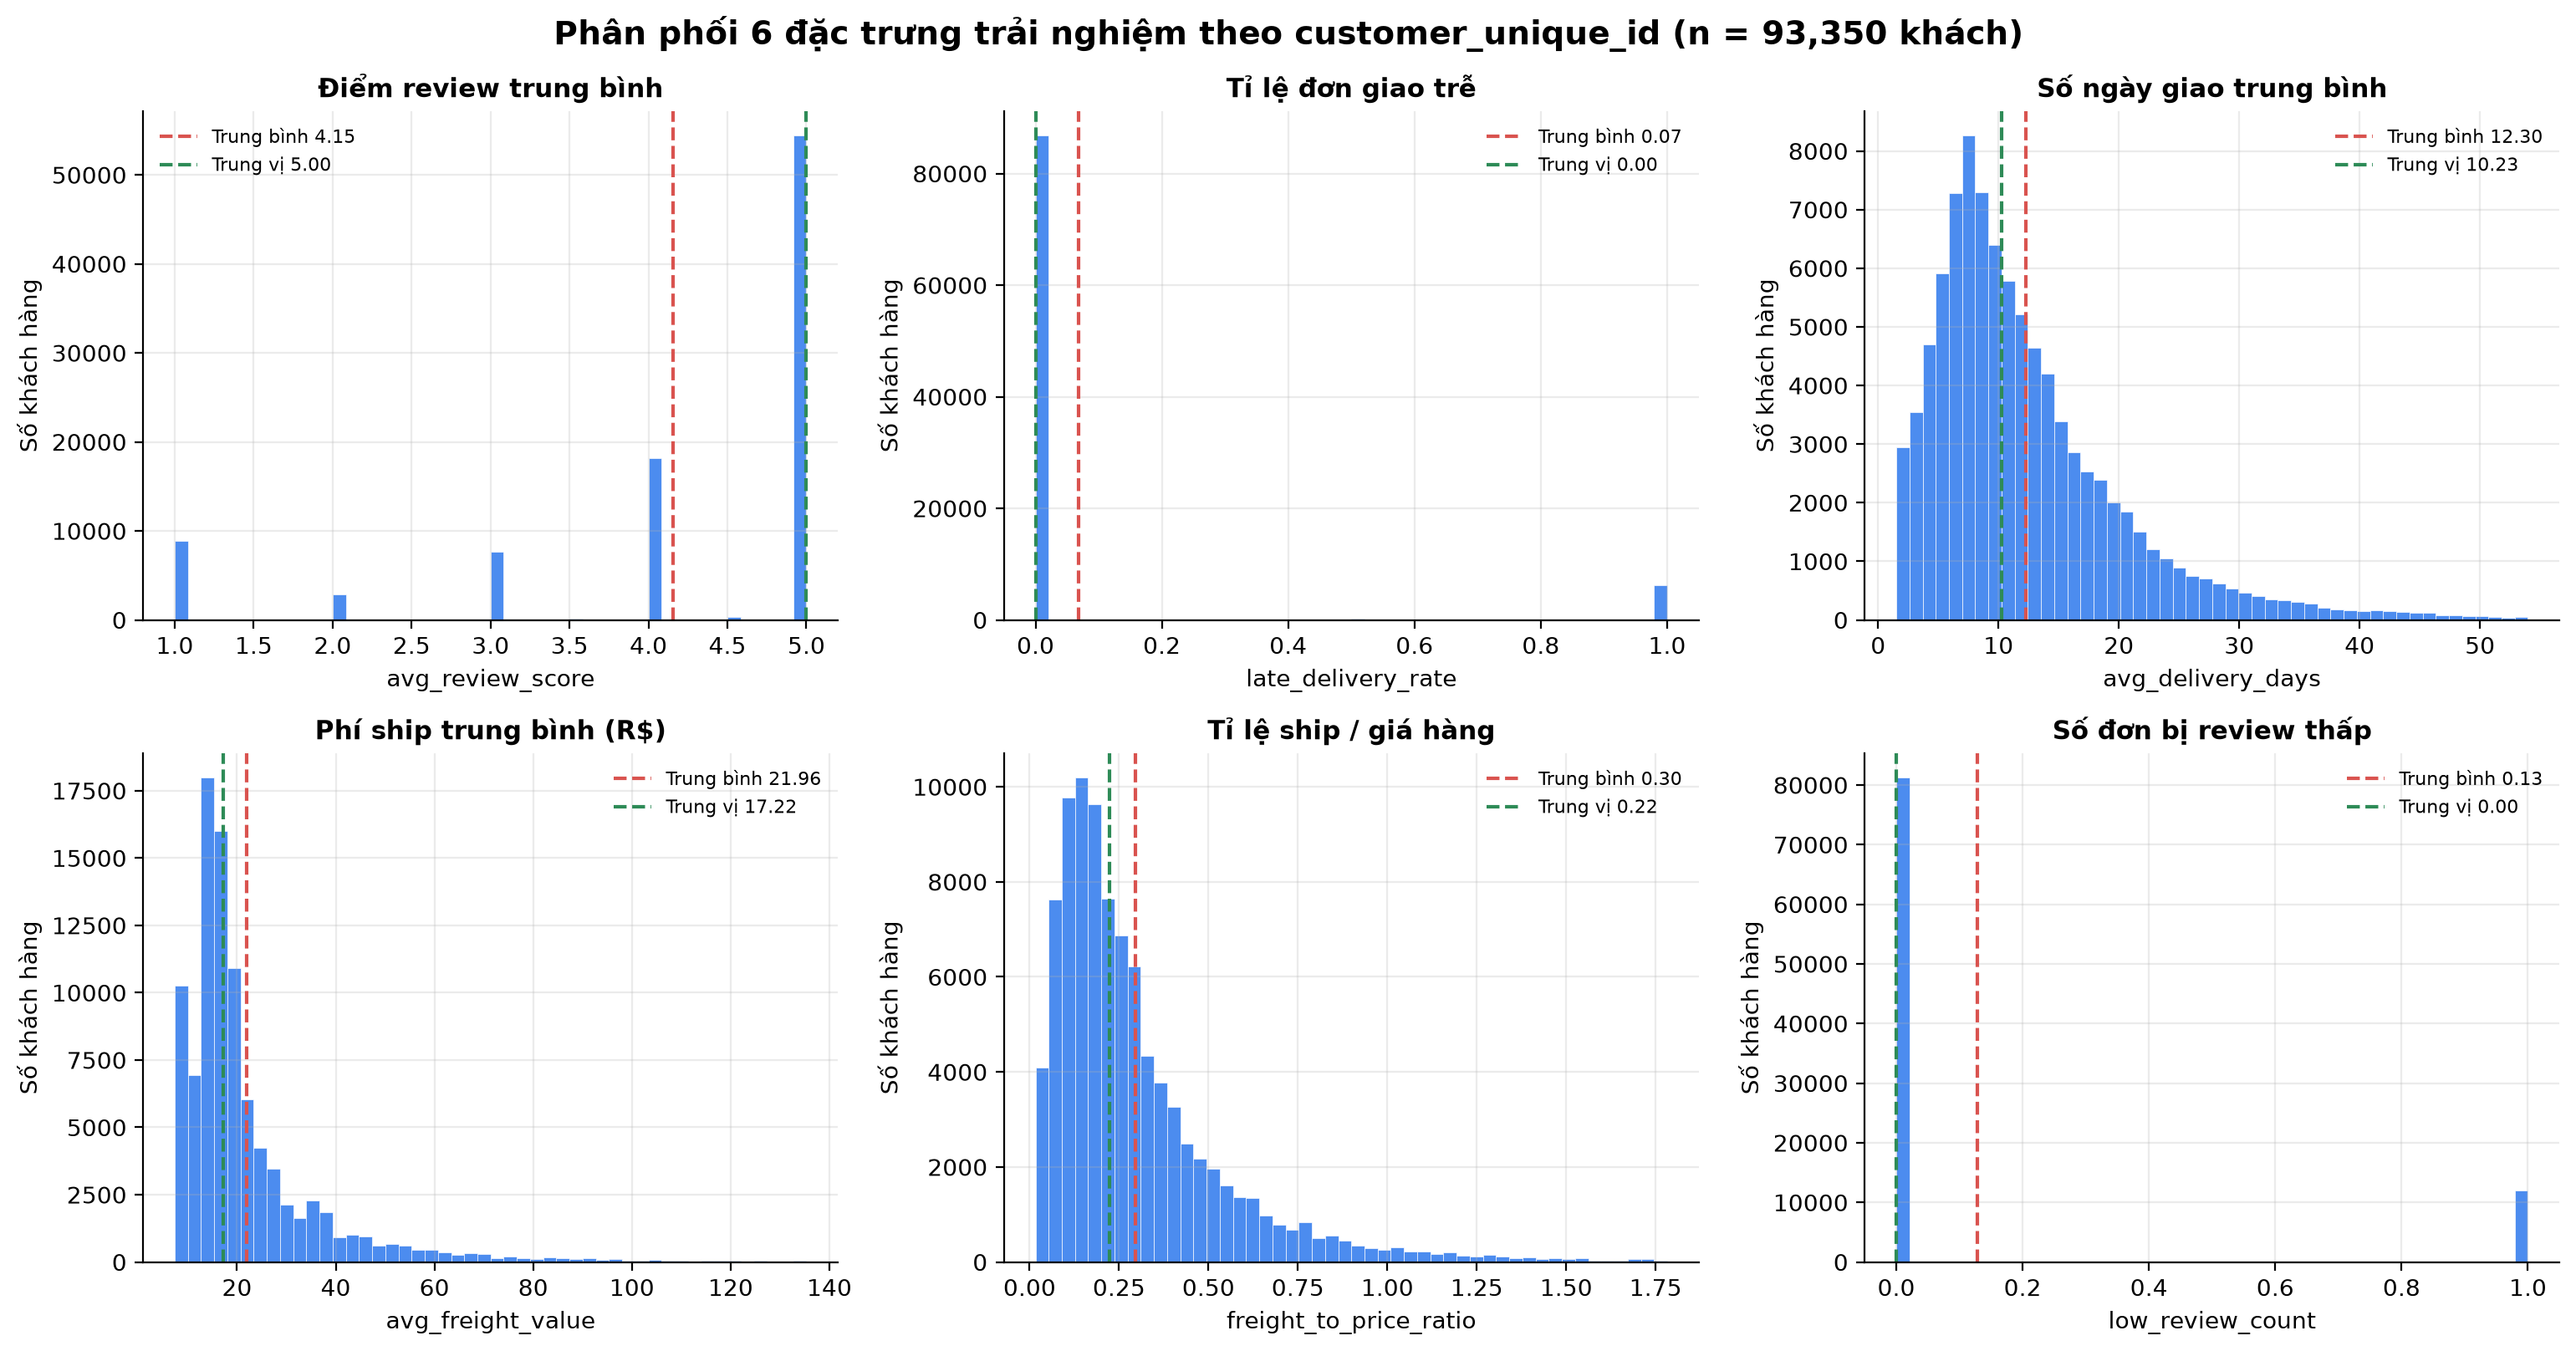

  -> đã lưu fig_08_phan_phoi_dac_trung.png


In [18]:
# --- Hình 8: phân phối 6 đặc trưng trải nghiệm ---------------------
multi = experience[experience["n_orders"] > 1]
fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.2))
titles = {
    "avg_review_score": "Điểm review trung bình",
    "late_delivery_rate": "Tỉ lệ đơn giao trễ",
    "avg_delivery_days": "Số ngày giao trung bình",
    "avg_freight_value": "Phí ship trung bình (R$)",
    "freight_to_price_ratio": "Tỉ lệ ship / giá hàng",
    "low_review_count": "Số đơn bị review thấp",
}
for ax, col in zip(axes.ravel(), titles):
    v = experience[col].dropna()
    v = v[v.between(v.quantile(0.005), v.quantile(0.995))]  # cắt đuôi 0.5% cho dễ nhìn
    ax.hist(v, bins=48, color=C_MAIN, alpha=0.8, edgecolor="white", linewidth=0.3)
    ax.axvline(v.mean(), color=C_LATE, linestyle="--",
               label=f"Trung bình {v.mean():.2f}")
    ax.axvline(v.median(), color=C_OK, linestyle="--", label=f"Trung vị {v.median():.2f}")
    ax.set_title(titles[col], fontsize=11)
    ax.set_xlabel(col)
    ax.set_ylabel("Số khách hàng")
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("Phân phối 6 đặc trưng trải nghiệm theo customer_unique_id "
             f"(n = {len(experience):,} khách)", fontsize=14, fontweight="bold")
fig.tight_layout()
print("Tương quan giữa các đặc trưng (Spearman, chỉ khách có review):")
mr = multi[multi["n_reviews"] > 0]
print(mr[feature_cols].corr(method="spearman").round(3))
savefig(fig, "fig_08_phan_phoi_dac_trung.png")

## Kiểm tra nhanh trước khi bàn giao

- [x] Chỉ dùng đơn `order_status = 'delivered'` và có đủ ngày giao thực tế.
- [x] Định danh khách hàng bằng `customer_unique_id` (không dùng `customer_id`).
- [x] `order_items` được SUM về mức đơn trước khi merge -> không nhân bản dòng.
- [x] Toàn bộ biểu đồ lưu PNG **dpi 200** tại `figures/`, nhãn đề bài tiếng Việt.
- [x] `experience_features.csv` có đúng một dòng cho mỗi `customer_unique_id`.

## Kết luận - các ý chính rút ra từ dữ liệu

1. **Đơn trễ hẹn hiếm nhưng rất "đắt":** chỉ 6.77% (6,534/96,470 đơn) về sau
   `order_estimated_delivery_date`, nhưng nhóm này bị chấm trung bình **2.27 sao** so với
   **4.29 sao** của nhóm đúng hạn — mất 2.02 sao,
   kiểm định Mann-Whitney U = 467,426,830, p-value xấp xỉ 0.
2. **Cột mốc "hẹn" của Olist rất rộng lượng:** trung vị `delay_days` =
   -12 ngày, nghĩa là đơn thường về **sớm hơn hẹn ~12 ngày**.
   Vì vậy 6.77% chỉ là phần đuôi; nếu siết lịch hẹn sát thực tế thì tỉ lệ trễ thực tăng lên,
   và `is_late` chỉ đáng tin khi đi kèm `delay_days`.
3. **Thời gian giao:** trung bình 12.6 ngày, trung vị
   10 ngày, P95 = 29 ngày,
   dài nhất 210 ngày => phân phối lệch phải mạnh,
   các đặc trưng `avg_delivery_days` nên được log/ Winsorize trước khi chuẩn hóa.
4. **Tác động của giao hàng là ngưỡng, không tuyến tính:** điểm review vẫn ~
   4.32 khi đơn về sớm hơn hẹn trên 8 ngày, nhưng rơi xuống
   3.29 (trễ 1-3 ngày), 2.11 (trễ 4-7 ngày) và
   1.70 (trễ trên 7 ngày). Tương quan hạng toàn cục vì thế nhỏ
   (rho delay = -0.176, rho thời gian giao = -0.235) —
   nên đưa vào mô hình **cờ trễ + khoảng trễ chia tổ** thay vì một biến liên tục.
5. **Review thiên lệch tích cực:** trung bình 4.16/5, 78.9% đơn đạt 4-5 sao,
   chỉ 12.77% đơn 1-2 sao (12,236 đơn) — đây chính là nhóm "khách hàng rủi ro"
   mà bài toán phân cụm cần tách ra.
6. **Phí ship khác nhau chủ yếu theo địa lý, ít liên hệ trực tiếp tới điểm đánh giá:**
   khu vực Norte chịu R$ 41.3/đơn so với R$
   19.8 ở Sudeste, nhưng Spearman(freight, review) chỉ -0.089;
   tổng phí ship bằng 16.6% tổng giá hàng, còn mức
   `freight_to_price_ratio` của một khách trung vị là 0.22.
   Bang BA có phí ship cao nhất trong 10 bang đông đơn nhất, còn
   SP chiếm 42.0% tổng đơn.
7. **Bảng đặc trưng đã sẵn sàng cho clustering:** 93,350 dòng tương ứng 93,350
   `customer_unique_id` (không trùng), 99.4% khách có ít nhất một review,
   603 khách không có review (để trống `NaN`, không điền 0).
8. **Cảnh giác với đặc trưng dư thừa:** 97.0% khách chỉ có 1 đơn nên
   `late_delivery_rate` và `avg_review_score` thực chất là biến nhị phân ở nhóm này
   (thị trường khách nhiều đơn chỉ 3.0%, n = 2,801);
   tương quan Spearman `late_delivery_rate`~`avg_review_score` = -0.301 và
   `low_review_count`~`avg_review_score` = -0.655. Trước khi chạy K-means/DBSCAN nên
   chuẩn hóa Z-score, loại bỏ `low_review_count` (hoặc `avg_review_score`) và cân nhắc PCA.

**Đầu ra của notebook:** `experience_features.csv`, `figures/` (8 PNG dpi 200),
`state_delivery_stats.csv` và file tóm tắt `tom_tat_y_chinh.md`.